# 02 · Look at 20 images, check for copies, make the split

README steps 2 and 4 (leakage check, block 5).

In [1]:
# Setup: works on Colab and on our own laptops.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("src"):
    !git clone https://github.com/Chandana18G/kvasir-seg-polyp-segmentation
    %cd kvasir-seg-polyp-segmentation
if os.path.basename(os.getcwd()) in ("chandana", "dinesh"):
    os.chdir("..")                      # run everything from the project folder
if not os.path.exists("data/Kvasir-SEG/images"):
    !python scripts/download_data.py    # 46 MB from datasets.simula.no
sys.path.insert(0, "src")

import numpy as np
import matplotlib.pyplot as plt
from data import list_names, load_image, load_mask, load_resized, read_split
os.makedirs("results", exist_ok=True)
from duplicates import dhash, close_pairs, mask_iou

## 1 · 20 images with their masks

A fixed random choice (seed 0), so we both see the same 20. Green = the doctor's mask.

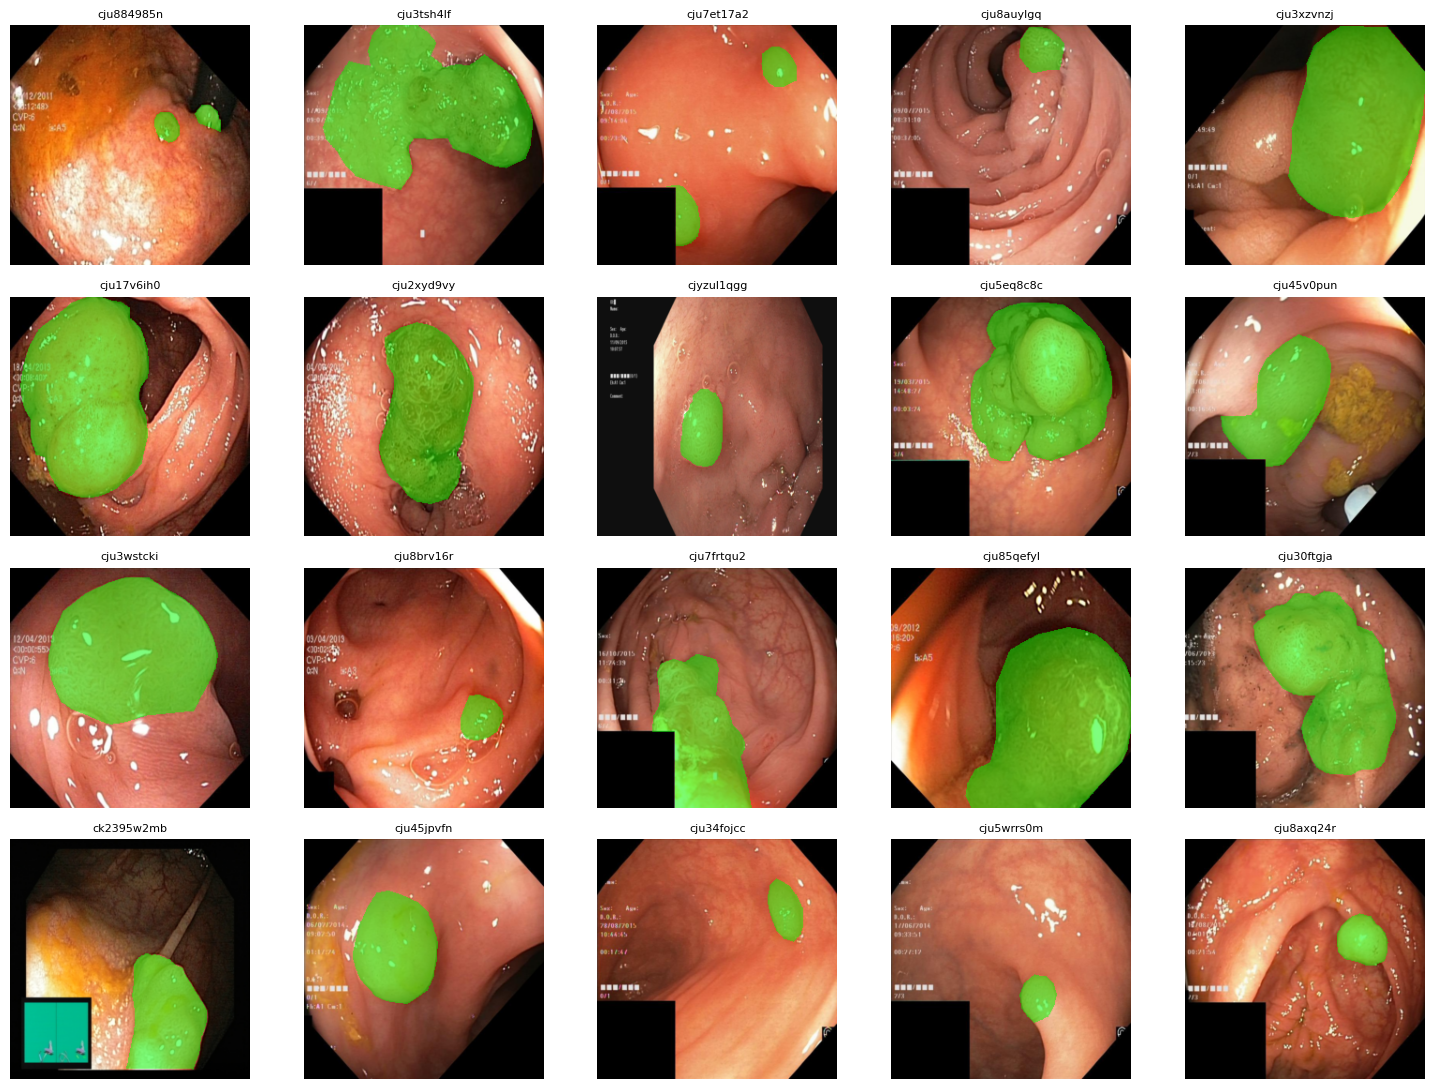

In [2]:
import random
names = list_names()
random.seed(0)
pick = random.sample(names, 20)

fig, axes = plt.subplots(4, 5, figsize=(15, 11))
for ax, name in zip(axes.flatten(), pick):
    image, mask = load_resized(name, 256)
    overlay = image.copy()
    overlay[mask == 1] = (0.5 * overlay[mask == 1] + [0, 127, 0]).astype(np.uint8)
    ax.imshow(overlay)
    ax.set_title(name[:10], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig("results/fig_20_examples.png", dpi=120)
plt.show()

**What we see by eye** (write down what *you* see; first notes from 19.11.):

- Black octagon border around every frame (the endoscope view).
- A **black box** in the bottom-left corner of many frames: the green position map
  (ScopeGuide) was blacked out by the dataset authors. But in **ck2395w2mb** the box is
  still there, in teal. Section 4 counts how often that happens.
- **Text** in the top-left of many frames: date, time, and fields like "Sex", "Age", "CVP".
- Light reflections (white spots) on the bowel wall and on polyps.
- Sometimes instruments (a snare or a cap) are in view.
- Polyp sizes vary from tiny to almost the whole frame.
- The masks look tight around the polyp; no obviously wrong mask in these 20 *(check)*.

## 2 · Copies: the same photo twice?

`src/duplicates.py` explains the method. First we look at the closest 25 pairs by
fingerprint, with how well their masks overlap.

25 pairs with fingerprint distance <= 3


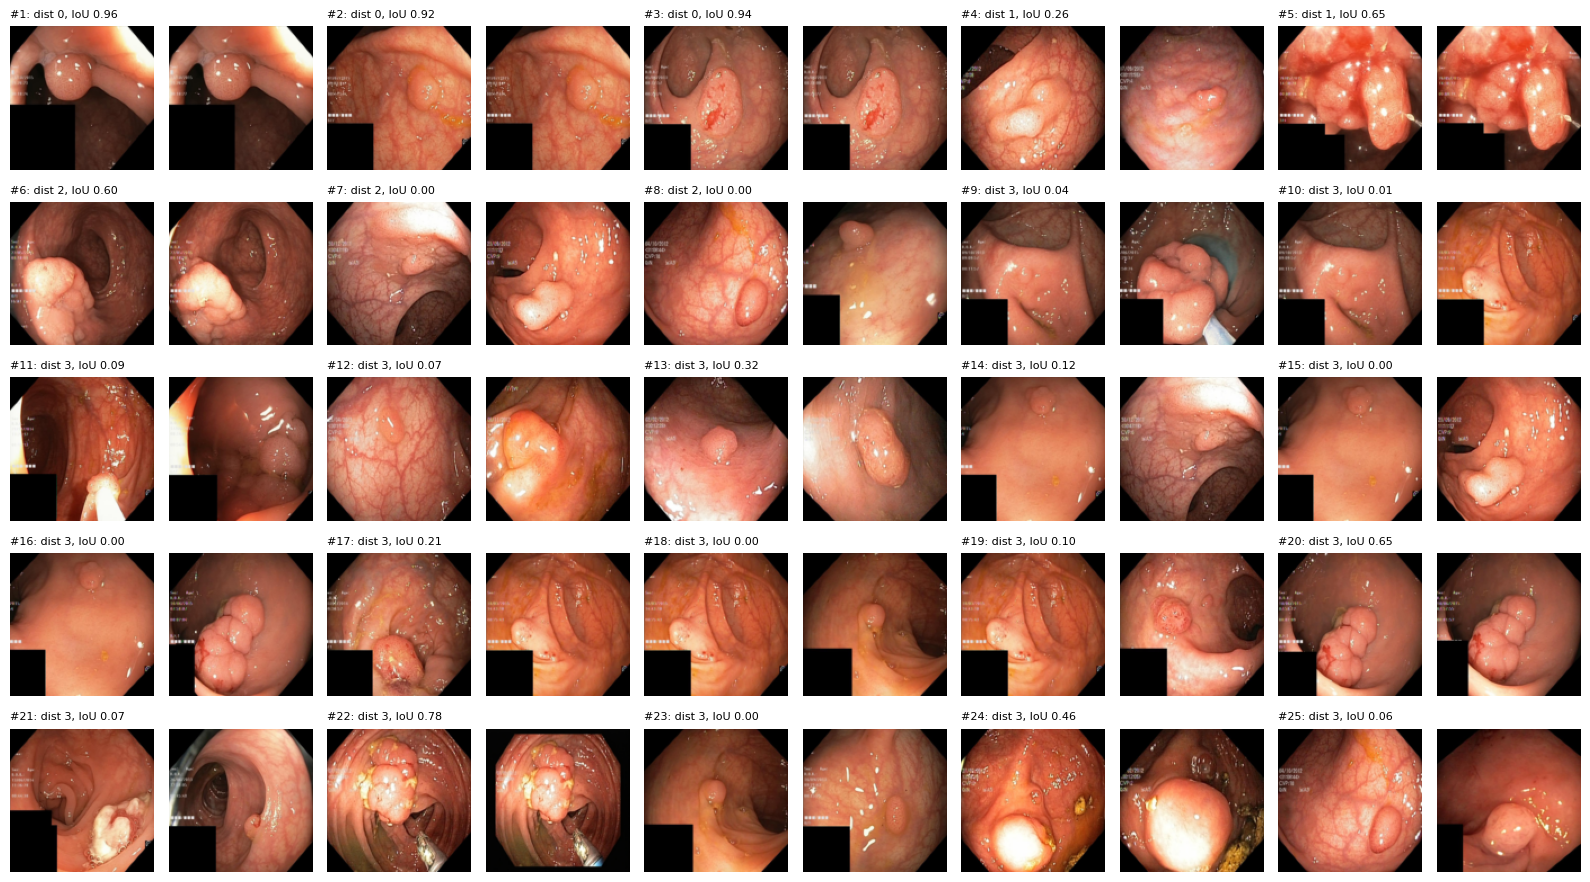

In [3]:
hashes = [dhash(load_image(n)) for n in names]
pairs = sorted(close_pairs(names, hashes, 3), key=lambda pair: pair[2])
print(len(pairs), "pairs with fingerprint distance <= 3")

# 5 rows of 5 pairs: each pair is two images side by side.
fig, axes = plt.subplots(5, 10, figsize=(16, 9))
for ax in axes.flatten():
    ax.axis("off")
for k, (a, b, distance) in enumerate(pairs[:25]):
    image_a, mask_a = load_resized(a, 128)
    image_b, mask_b = load_resized(b, 128)
    iou = mask_iou(mask_a, mask_b)
    row, col = k // 5, 2 * (k % 5)
    axes[row, col].imshow(image_a)
    axes[row, col + 1].imshow(image_b)
    axes[row, col].set_title(f"#{k + 1}: dist {distance}, IoU {iou:.2f}", fontsize=8, loc="left")
plt.tight_layout()
plt.savefig("results/fig_closest_pairs.png", dpi=100)
plt.show()

**What we decided from these pictures:** pairs with distance ≤ 3 **and** mask IoU ≥ 0.5
are the same photo or nearly the same frame of the same polyp. All other pairs show
different polyps (the black border alone makes their fingerprints similar).

### Mirrored copies?
Same test, but we flip the second image (and its mask) first.

In [4]:
from duplicates import MAX_DISTANCE, MIN_MASK_IOU
flips = {"left-right": lambda x: x[:, ::-1], "up-down": lambda x: x[::-1]}
for flip_name, flip in flips.items():
    flipped_hashes = [dhash(flip(load_image(n))) for n in names]
    found = []
    for i in range(len(names)):
        for j in range(len(names)):
            if i != j and (hashes[i] != flipped_hashes[j]).sum() <= MAX_DISTANCE:
                mask_a = load_resized(names[i], 160)[1]
                mask_b = flip(load_resized(names[j], 160)[1])
                if mask_iou(mask_a, mask_b) >= MIN_MASK_IOU:
                    found.append((names[i], names[j]))
    print(flip_name, len(found), found)

left-right 2 [('cju17g6ykn1cs0993dww6qdi8', 'cju88y1mwoln50871emyfny1g'), ('cju2zr3c3vwb00993jn06bbaz', 'cju88t4fvokxf07558ymyh281')]


up-down 0 []


We looked at the left-right candidates by eye: **neither is a mirrored copy**. The text
in the corner is not mirrored. The first pair shows two different polyps. The second pair
(cju2zr3c..., cju88t4f...) is the **same polyp on the same date from another angle**: the
same patient can appear more than once, and our check does not catch every such frame.
This pair is split: cju2zr3c... is in **train** and cju88t4f... is in **validation**. We keep
it there and name it as a limitation: validation is only used to choose the epoch and the
threshold, and one shared polyp out of 100 validation images changes little. The test set
is not affected by this pair.

`scripts/make_split.py` applies the rule (unflipped). Its result:

In [5]:
import csv
with open("results/duplicates.csv") as f:
    duplicates = list(csv.DictReader(f))
print(len(duplicates), "near-duplicate pairs")
for row in duplicates:
    print(row)

7 near-duplicate pairs
{'image_a': 'cju1cj3f0qi5n0993ut8f49rj', 'image_b': 'cju7ev2b12owa08500bpfpwyw', 'hash_distance': '2', 'mask_iou': '0.6'}
{'image_a': 'cju30bmab08bi0835mvlr6e0r', 'image_b': 'cju77k828z46w0871r0avuoo9', 'hash_distance': '0', 'mask_iou': '0.96'}
{'image_a': 'cju42dwedlmk60871jbgu4ehi', 'image_b': 'cju43b8daly4408170e5ev06g', 'hash_distance': '3', 'mask_iou': '0.64'}
{'image_a': 'cju5fydrud94708507vo6oy21', 'image_b': 'cju7avvi51iox0817ym55y6tt', 'hash_distance': '1', 'mask_iou': '0.65'}
{'image_a': 'cju5jx7jzf7c90871c2i9aiov', 'image_b': 'cjyzl833ndne80838pzuq6ila', 'hash_distance': '3', 'mask_iou': '0.79'}
{'image_a': 'cju76lsehyia10987u54vn8rb', 'image_b': 'cju772304yw5t0818vbw8kkjf', 'hash_distance': '0', 'mask_iou': '0.93'}
{'image_a': 'cju886ryxnsl50801r93jai7q', 'image_b': 'cju8amfdtqi4x09871tygrgqe', 'hash_distance': '0', 'mask_iou': '0.95'}


## 3 · The split

In [6]:
for split in ["train", "val", "test"]:
    print(split, len(read_split(split)))
print("dropped (copy of a test image):", read_split("dropped"))

# Check: no image in two splits, and no near-copy across splits.
train, val, test = set(read_split("train")), set(read_split("val")), set(read_split("test"))
assert not (train & val) and not (train & test) and not (val & test)
where = {}
for split, members in [("train", train), ("val", val), ("test", test)]:
    for name in members:
        where[name] = split
for row in duplicates:
    a, b = row["image_a"], row["image_b"]
    print(f"{where.get(a, 'dropped'):8s} {where.get(b, 'dropped'):8s}")

train 779
val 100
test 120
dropped (copy of a test image): ['cju5jx7jzf7c90871c2i9aiov']
train    train   
train    train   
train    train   
train    train   
dropped  test    
train    train   
train    train   


## 4 · Is the test set like the training set?

Two checks: (1) how many images still show the coloured position box (many green/teal
pixels in the bottom-left corner), and (2) the first letters of the file names. The
names look like time-ordered IDs, so a new prefix may mean a later batch of images
(our guess; the dataset does not say).

In [7]:
def has_coloured_box(image):
    h, w, _ = image.shape
    corner = image[int(h * 0.55):, :int(w * 0.4)].astype(int)
    red, green, blue = corner[:, :, 0], corner[:, :, 1], corner[:, :, 2]
    teal = (green > red + 60) & (blue > red + 40) & (green > 120)
    return teal.mean() > 0.03          # more than 3 % of the corner is teal/green

LATER_BATCH = ("cjyz", "cjz1", "ck23", "ck2b", "ck2d")
for split in ["train", "val", "test"]:
    split_names = read_split(split)
    boxes = sum(has_coloured_box(load_image(n)) for n in split_names)
    later = sum(n[:4] in LATER_BATCH for n in split_names)
    print(f"{split:5s}: {len(split_names)} images, coloured box in {boxes}, "
          f"names from the later batch: {later}")

train: 779 images, coloured box in 0, names from the later batch: 0


val  : 100 images, coloured box in 0, names from the later batch: 0


test : 120 images, coloured box in 13, names from the later batch: 23


**Result:** the coloured box appears only in the test set (13 of 120), and 23 test images
come from a batch that has no images in train or validation. The test set is therefore a
little different from what the network learns on. We will also report test Dice for these
23 images separately, as a small check of how the model copes with new images.